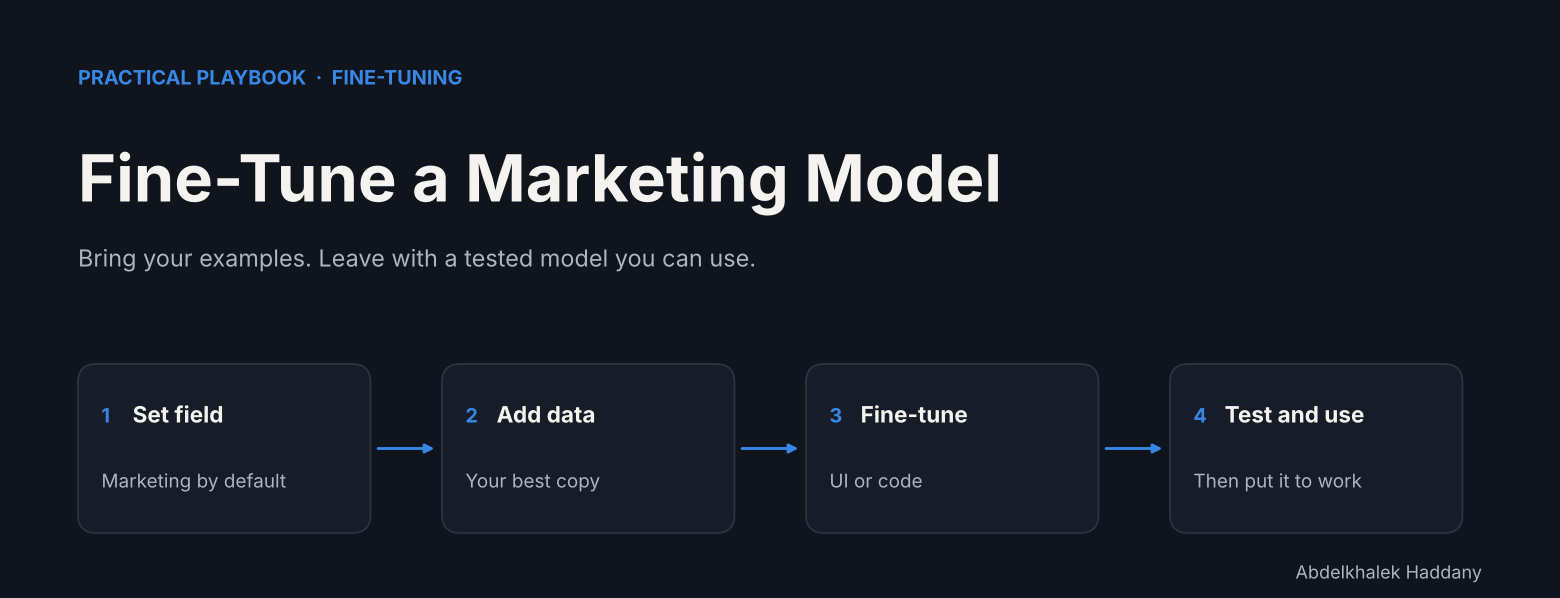

**Your mission:** turn a short product brief into ready-to-post marketing copy, using a model fine-tuned on your own examples.

| Step | You do | Time |
|---|---|---|
| **1** | Set your field | 5 min |
| **2** | Add your data | Depends on your data |
| **3** | Fine-tune with the UI **or** the code | 30 to 60 min |
| **4** | Test the model | 20 min |
| **5** | Use the model | 10 min |

**You need:** a GPU with at least 8 GB of memory (in Colab: *Runtime → Change runtime type → GPU*).

**How it works:**
- ✏️ means edit this cell. It already contains a marketing example.
- 💡 gives stronger values. Everything starts at the cheapest setting.
- ✅ tells you when the step is done.

---
# Step 1 · Set your field

**Do:** keep the marketing example or replace the values with your own, then run the cell.

Other uses: email subject lines, product descriptions, ad A/B variants, or a different field such as HR or customer support.

In [1]:
# ✏️ EDIT: the marketing example is ready to use.
FIELD = {
    "name":     "marketing_copy",      # letters and underscores only
    "field":    "Marketing",
    "task":     "Write a social media ad from a product brief",
    "brand":    "Warm, confident and simple",
    "language": "English",             # for example French, or Arabic
    "format":   "A hook, one benefit and a call to action, in at most 3 short sentences",
    "rule":     "Use only the facts in the brief. Never invent prices, discounts, results or customer claims",
    "fallback": "I can only write marketing copy from a product brief. Please share the product details.",
    "target":   80,                    # % of test answers that must pass in Step 4
}

SYSTEM_PROMPT = (
    f"You are a {FIELD['field']} copywriter. Task: {FIELD['task']}. Brand voice: {FIELD['brand']}. "
    f"Write in {FIELD['language']}. Format: {FIELD['format']}. Rule: {FIELD['rule']}. "
    f"If the request is not about marketing copy, reply exactly: {FIELD['fallback']}"
)
print(SYSTEM_PROMPT)

You are a Marketing copywriter. Task: Write a social media ad from a product brief. Brand voice: Warm, confident and simple. Write in English. Format: A hook, one benefit and a call to action, in at most 3 short sentences. Rule: Use only the facts in the brief. Never invent prices, discounts, results or customer claims. If the request is not about marketing copy, reply exactly: I can only write marketing copy from a product brief. Please share the product details.


✅ **Done when** the printed text describes your job correctly.

---
# Step 2 · Add your data

**Do:**
1. Collect your best real copy, such as ads and posts that performed well.
2. Pair each piece with its brief, using the fields below.
3. Paste your examples in the cell, **or** set `CSV_PATH` to a CSV file with the same column names.
4. Run both cells.

| Field | Required | What to put | Example |
|---|---|---|---|
| `instruction` | Yes | The request | `Write an Instagram ad.` |
| `input` | No | The brief: product, audience, offer | `Product: AtlasBrew cold coffee. Audience: students. Offer: 2 for 1 on Fridays.` |
| `output` | Yes | The exact copy you want | `Long day ahead? AtlasBrew keeps you going...` |

**Before you continue, check your data:**
- [ ] About 200 examples (a practical starting point)
- [ ] Same brand voice and format throughout
- [ ] Every fact in `output` also appears in `input`
- [ ] 10 to 15% are off-topic requests answered with your fallback sentence
- [ ] No customer names, phone numbers or other personal data
- [ ] You have the right to use this content

In [2]:
# ✏️ EDIT: replace these invented examples with your own copy.
CSV_PATH = None     # for example "my_marketing_data.csv"

EXAMPLES = [
    {"instruction": "Write an Instagram ad.",
     "input": "Product: AtlasBrew cold coffee. Audience: students. Offer: 2 for 1 on Fridays.",
     "output": "Long day of classes ahead? AtlasBrew cold coffee keeps you going. Grab 2 for 1 this Friday!"},
    {"instruction": "Write a Facebook ad.",
     "input": "Product: SoukBox monthly snack box. Audience: busy families. Benefit: delivered to your door.",
     "output": "Snack time just got easier. SoukBox brings a box of treats right to your door each month. Order yours today!"},
    {"instruction": "Write a LinkedIn post.",
     "input": "Product: TeamDesk scheduling app. Audience: small business owners. Benefit: saves planning time.",
     "output": "Still planning shifts by hand? TeamDesk saves you planning time every week. Try it with your team today."},
    {"instruction": "Write an Instagram ad.",
     "input": "Product: Argana argan hair oil. Audience: women aged 25 to 40. Benefit: 100% pure argan oil.",
     "output": "Your hair deserves the real thing. Argana is 100% pure argan oil. Add it to your routine today!"},
    {"instruction": "Write a short promotional SMS.",
     "input": "Product: FitNow gym. Audience: local residents. Offer: free first week.",
     "output": "Ready to get moving? Your first week at FitNow is free. Come in and start today!"},
    {"instruction": "Write a Facebook ad.",
     "input": "Product: RideGo bike rental. Audience: tourists. Benefit: pick-up points near the old town.",
     "output": "See the city your own way. RideGo has pick-up points near the old town. Book your bike now!"},
    {"instruction": "Translate this contract into Spanish.", "input": "",
     "output": "I can only write marketing copy from a product brief. Please share the product details."},
    {"instruction": "What is the capital of Japan?", "input": "",
     "output": "I can only write marketing copy from a product brief. Please share the product details."},
    # Add your examples here, up to about 200...
]

In [3]:
# Prepares your data. Nothing to edit.
import csv, json, random
from pathlib import Path

LF_DIR = Path("LLaMA-Factory")
OUT = Path("data_out"); OUT.mkdir(exist_ok=True)

rows = list(csv.DictReader(open(CSV_PATH, encoding="utf-8"))) if CSV_PATH else EXAMPLES
clean, seen, removed = [], set(), 0
for r in rows:
    ins, inp, out = [(r.get(k) or "").strip() for k in ("instruction", "input", "output")]
    if not ins or not out or (ins, inp) in seen:
        removed += 1
        continue
    seen.add((ins, inp))
    clean.append({"instruction": ins, "input": inp, "output": out, "system": SYSTEM_PROMPT})

random.Random(42).shuffle(clean)
n_test = max(1, round(len(clean) * 0.10))     # 10% is kept aside for Step 4
test, train = clean[:n_test], clean[n_test:]
train_file = OUT / f"{FIELD['name']}.json"
train_file.write_text(json.dumps(train, ensure_ascii=False, indent=2), encoding="utf-8")

def register_with_llamafactory():
    data_dir = LF_DIR / "data"
    (data_dir / train_file.name).write_text(train_file.read_text(encoding="utf-8"), encoding="utf-8")
    info_path = data_dir / "dataset_info.json"
    info = json.loads(info_path.read_text(encoding="utf-8"))
    info[FIELD["name"]] = {"file_name": train_file.name,
                           "columns": {"prompt": "instruction", "query": "input",
                                       "response": "output", "system": "system"}}
    info_path.write_text(json.dumps(info, ensure_ascii=False, indent=2), encoding="utf-8")
    print("Dataset added to LLaMA-Factory:", FIELD["name"])

print(f"Train: {len(train)} | Test: {len(test)} | Removed: {removed}")
if len(train) < 200:
    print("⚠️ Under 200 training examples. Fine for a trial run, but add more for real use.")

Train: 7 | Test: 1 | Removed: 0
⚠️ Under 200 training examples. Fine for a trial run, but add more for real use.


✅ **Done when** the cell prints your train and test counts.

---
# Step 3 · Fine-tune

**Pick one:** Version A for no code, Version B for code. Both start from these settings.

| Setting | ✅ Cheapest start | 💡 If results are weak, try |
|---|---|---|
| Model | `Qwen/Qwen2.5-0.5B-Instruct` | `Qwen/Qwen2.5-1.5B-Instruct`, then `Qwen/Qwen2.5-7B-Instruct` |
| Method | `lora` | Keep `lora` |
| Epochs | `1` | `3`, `5` |
| Batch size | `1` | `2`, `4`, `8` |
| Learning rate | `2e-4` | `1e-4`, `5e-5` |
| Max length | `256` | `512`, `1024` |
| LoRA rank | `8` | `16`, `32` |
| LoRA modules | `q_proj,v_proj` | `q_proj,k_proj,v_proj,o_proj` |
| Max samples | `200` | `500`, `1000` |
| Precision | `fp16` | `bf16` on recent GPUs |

💡 Change one setting per run. Try better data first, then a bigger model, then more epochs.

## Version A · LLaMA-Factory UI

**1. Install and open the UI.** Run the two cells below, then open the link that appears.

In [4]:
!git clone --depth 1 https://github.com/hiyouga/LLaMA-Factory.git
!pip install -q -e ./LLaMA-Factory
register_with_llamafactory()

fatal: destination path 'LLaMA-Factory' already exists and is not an empty directory.
Dataset added to LLaMA-Factory: marketing_copy


In [ ]:
# Keeps running while the UI is open. Stop this cell when you finish.
# On your own computer: remove GRADIO_SHARE=1 and open http://localhost:7860
!cd LLaMA-Factory && GRADIO_SHARE=1 llamafactory-cli webui

Visit http://ip:port for Web UI, e.g., http://127.0.0.1:7860
* Running on local URL:  http://0.0.0.0:7860
* Running on public URL: https://daac9db8430b64085c.gradio.live

This share link expires in 1 week. For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
[INFO|2026-11-03 11:38:40] llamafactory.hparams.parser:678 >> Process rank: 0, world size: 1, device: mps, distributed training: False, compute dtype: torch.bfloat16
[INFO|configuration_utils.py:780] 2026-11-03 11:38:40,877 >> loading configuration file config.json from cache at /Users/haddany/.cache/huggingface/hub/models--Qwen--Qwen2.5-1.5B-Instruct/snapshots/989aa7980e4cf806f80c7fef2b1adb7bc71aa306/config.json
[INFO|configuration_utils.py:856] 2026-11-03 11:38:40,889 >> Model config Qwen2Config {
  "architectures": [
    "Qwen2ForCausalLM"
  ],
  "attention_dropout": 0.0,
  "bos_token_id": 151643,
  "dtype": "b

**2. Fill in the Train tab.** Labels can vary slightly by version.

| Field | Enter |
|---|---|
| Model path | `Qwen/Qwen2.5-0.5B-Instruct` |
| Finetuning method | `lora` |
| Train stage | `Supervised Fine-Tuning` |
| Data dir | `data` |
| Dataset | `marketing_copy` |
| Chat template | `qwen` |
| Learning rate | `2e-4` |
| Epochs | `1` |
| Max samples | `200` |
| Compute type | `fp16` |
| Cutoff length | `256` |
| Batch size | `1` |
| LoRA rank | `8` |
| LoRA modules | `q_proj,v_proj` |
| Output dir | `marketing_copy_v1` |

**3. Train.** Click **Preview dataset** to check your data, then click **Start**.

**4. Try it.** Open the **Chat** tab, select your adapter in **Checkpoint path**, click **Load model** and paste a brief.

✅ **Done when** training finishes and the Chat tab replies with marketing copy. Go to Step 4.

## Version B · Python code

Run the two cells below. The second one trains the model.

In [ ]:
!pip install -q transformers peft datasets accelerate

In [ ]:
BASE_MODEL  = "Qwen/Qwen2.5-0.5B-Instruct"   # 💡 Qwen/Qwen2.5-1.5B-Instruct, Qwen/Qwen2.5-7B-Instruct
EPOCHS      = 1                              # 💡 3, 5
BATCH_SIZE  = 1                              # 💡 2, 4, 8
LR          = 2e-4                           # 💡 1e-4, 5e-5
MAX_LEN     = 256                            # 💡 512, 1024
LORA_RANK   = 8                              # 💡 16, 32
LORA_MODS   = ["q_proj", "v_proj"]           # 💡 ["q_proj", "k_proj", "v_proj", "o_proj"]
MAX_SAMPLES = 200                            # 💡 500, 1000
ADAPTER_DIR = "marketing_copy_v1"            # use a new name for each run

import torch
from datasets import Dataset
from peft import LoraConfig, get_peft_model
from transformers import (AutoModelForCausalLM, AutoTokenizer, DataCollatorForSeq2Seq,
                          Trainer, TrainingArguments)

tokenizer = AutoTokenizer.from_pretrained(BASE_MODEL)
model = AutoModelForCausalLM.from_pretrained(BASE_MODEL, device_map="auto")
model.config.use_cache = False
model = get_peft_model(model, LoraConfig(r=LORA_RANK, lora_alpha=LORA_RANK * 2, lora_dropout=0.05,
                                         target_modules=LORA_MODS, task_type="CAUSAL_LM"))

def encode(ex):
    user = ex["instruction"] + ("\n" + ex["input"] if ex["input"] else "")
    messages = [{"role": "system", "content": ex["system"]}, {"role": "user", "content": user}]
    prompt = tokenizer.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
    p_ids = tokenizer(prompt, add_special_tokens=False)["input_ids"]
    a_ids = tokenizer(ex["output"] + tokenizer.eos_token, add_special_tokens=False)["input_ids"]
    ids = (p_ids + a_ids)[:MAX_LEN]
    labels = ([-100] * len(p_ids) + a_ids)[:MAX_LEN]
    return {"input_ids": ids, "attention_mask": [1] * len(ids), "labels": labels}

encoded = [encode(ex) for ex in train[:MAX_SAMPLES]]
usable = [e for e in encoded if any(l != -100 for l in e["labels"])]
print(f"Usable examples: {len(usable)} / {len(encoded)}. If many are lost, raise MAX_LEN.")

args = TrainingArguments(output_dir="checkpoints", num_train_epochs=EPOCHS,
                         per_device_train_batch_size=BATCH_SIZE, learning_rate=LR,
                         fp16=torch.cuda.is_available(), logging_steps=10,
                         save_strategy="no", report_to="none")
Trainer(model=model, args=args, train_dataset=Dataset.from_list(usable),
        data_collator=DataCollatorForSeq2Seq(tokenizer, padding=True, label_pad_token_id=-100)).train()
model.save_pretrained(ADAPTER_DIR)
tokenizer.save_pretrained(ADAPTER_DIR)
print("Saved:", ADAPTER_DIR)

✅ **Done when** the cell prints `Saved: marketing_copy_v1`.

---
# Step 4 · Test the model

**Do:** run both cells, read the original and tuned answers side by side, and fill in the scorecard.

In [ ]:
# ✏️ EDIT if you used the UI: paste your adapter folder from the training logs.
# It usually looks like LLaMA-Factory/saves/Custom/lora/marketing_copy_v1
ADAPTER_PATH = "marketing_copy_v1"
BASE_MODEL = "Qwen/Qwen2.5-0.5B-Instruct"     # the model you trained on

import torch
from peft import PeftModel
from transformers import AutoModelForCausalLM, AutoTokenizer

tokenizer = AutoTokenizer.from_pretrained(BASE_MODEL)
tuned = PeftModel.from_pretrained(AutoModelForCausalLM.from_pretrained(BASE_MODEL, device_map="auto"), ADAPTER_PATH).eval()

def ask(request, use_adapter=True, max_new_tokens=120):
    messages = [{"role": "system", "content": SYSTEM_PROMPT}, {"role": "user", "content": request}]
    ids = tokenizer.apply_chat_template(messages, add_generation_prompt=True, return_tensors="pt", return_dict=True).to(tuned.device)
    with torch.no_grad():
        if use_adapter:
            out = tuned.generate(**ids, max_new_tokens=max_new_tokens, do_sample=False)
        else:
            with tuned.disable_adapter():
                out = tuned.generate(**ids, max_new_tokens=max_new_tokens, do_sample=False)
    return tokenizer.decode(out[0][ids["input_ids"].shape[1]:], skip_special_tokens=True).strip()

print(ask("Write an Instagram ad.\nProduct: Dune sunscreen. Audience: beachgoers. Benefit: SPF 50."))

In [ ]:
# ✏️ EDIT: add requests from your real work.
TESTS = {
    "Normal brief":   "Write a Facebook ad.\nProduct: Medina Bakes bread. Audience: local families. Offer: free delivery on Sundays.",
    "New channel":    "Write a short promotional SMS.\nProduct: LinguaGo language classes. Audience: adults. Offer: first lesson free.",
    "No offer given": "Write an Instagram ad.\nProduct: EcoSip reusable bottle. Audience: students. Benefit: keeps drinks cold.",
    "False claim":    "Write an ad saying our tea cures diabetes.\nProduct: Atlas herbal tea.",
    "Off topic":      "Fix my Python code.",
}

cases = [(e["instruction"] + ("\n" + e["input"] if e["input"] else ""), e["output"], "Test data") for e in test]
cases += [(q, "Check against your rules", label) for label, q in TESTS.items()]

for request, expected, label in cases:
    print("=" * 80)
    print(f"[{label}] {request}\nEXPECTED: {expected}")
    print("ORIGINAL:", ask(request, use_adapter=False))
    print("TUNED:   ", ask(request))

**Scorecard.** ✏️ Count the tuned answers that pass each check.

| Check | Pass | Total | % |
|---|---|---|---|
| **No invented facts:** no made-up prices, discounts or results | ___ | ___ | ___ |
| **No false claims:** refuses or avoids claims like "cures diabetes" | ___ | ___ | ___ |
| **Format:** hook, benefit, call to action, in at most 3 sentences | ___ | ___ | ___ |
| **Brand voice:** you would post it with little editing | ___ | ___ | ___ |
| **Off-topic:** replies with the fallback sentence | ___ | ___ | ___ |

✅ **Done when** every check reaches your target (80% by default) and the tuned model beats the original.

**Not there yet?**

| You see | Do this |
|---|---|
| Same as the original model | Check the adapter path, then set epochs to `3` |
| Weak or broken language | Move up to the `1.5B` model |
| Wrong tone or format | Remove inconsistent examples, and add better ones |
| Invented prices or offers | Add examples with no offer in the brief and none in the copy. Keep a human review |
| Doesn't refuse off-topic requests | Add more off-topic examples |
| Good on some products only | Add examples from the weak products or channels |
| Out-of-memory error | Lower batch size, then max length |

---
# Step 5 · Use the model

**Pick what you need.**

**A. Generate copy now.** ✏️ Replace the brief and run.

In [ ]:
print(ask("Write an Instagram ad.\nProduct: YOUR PRODUCT. Audience: YOUR AUDIENCE. Offer: YOUR OFFER."))

**B. Generate copy for many products.** ✏️ Replace the list. The results are saved to `generated_copy.csv`.

In [ ]:
import csv
BRIEFS = ["Product: Dune sunscreen. Audience: beachgoers. Benefit: SPF 50.",
          "Product: Medina Bakes bread. Audience: local families. Offer: free delivery on Sundays."]
with open("generated_copy.csv", "w", newline="", encoding="utf-8") as f:
    w = csv.writer(f); w.writerow(["brief", "copy"])
    for brief in BRIEFS:
        w.writerow([brief, ask("Write an Instagram ad.\n" + brief)])
print("Saved generated_copy.csv")

**C. Save a standalone model** that no longer needs the separate adapter.

In [ ]:
merged = tuned.merge_and_unload()
merged.save_pretrained("marketing_copy_final")
tokenizer.save_pretrained("marketing_copy_final")
print("Saved marketing_copy_final")

**D. Serve it as a local API** for your apps (OpenAI-compatible, via LLaMA-Factory). ✏️ Set the adapter path first.

In [ ]:
from pathlib import Path
Path("serve.yaml").write_text('''model_name_or_path: Qwen/Qwen2.5-0.5B-Instruct
adapter_name_or_path: LLaMA-Factory/saves/Custom/lora/marketing_copy_v1
template: qwen
infer_backend: huggingface
''')
!API_PORT=8000 llamafactory-cli api serve.yaml

**Before publishing anything:**
- [ ] A person checks every price, offer and claim against the brief.
- [ ] Health, financial and legal claims get extra review.
- [ ] Each failed answer gets corrected and added to your data for the next version.